<a href="https://colab.research.google.com/github/justleein2/MachineLearning/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1:


In [1]:
import pandas as pd
import numpy as np
import zipfile

columns = ['age','sex','cp','trestbps','chol','fbs','restecg',
           'thalach','exang','oldpeak','slope','ca','thal','target']

df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data", names=columns, na_values="?", header=None)

Task 2:

In [2]:
print(df.info())

print("\n...Summary Statistics...")

display(df.describe())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
None

...Summary Statistics...


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  


In [3]:
print(df.columns.tolist())
print(df.shape)


['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
(303, 14)


Task 3:

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

mi = df.isnull().sum()

numeric_features     = ['age','trestbps','chol','thalach','oldpeak']
categorical_features = ['sex','cp','fbs','restecg','exang','slope','ca','thal']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

Task 4

In [5]:
from sklearn.model_selection import train_test_split

for col in categorical_features:
    df[col] = df[col].astype(str).replace('nan', np.nan)

X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_prep = preprocessor.fit_transform(X_train)
print("Shape:", X_train_prep.shape)

Shape: (242, 28)


Task 5:

In [6]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

#Fixed by Gemini
# Create and fit the pipeline (which includes preprocessing with imputation)
svc_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
])

svc_pipeline.fit(X_train, y_train)

y_pred_svc  = svc_pipeline.predict(X_test)
# Predict probabilities for all classes using the pipeline
y_proba_svc = svc_pipeline.predict_proba(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svc))

print("Classification Report:")
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4']
print(classification_report(y_test, y_pred_svc, target_names=class_names))

# Calculate ROC-AUC using the probabilities from the pipeline
roc_auc = roc_auc_score(y_test, y_proba_svc, multi_class="ovr", average="macro")
print(f"ROC-AUC: {roc_auc:.4f}")

Confusion Matrix:
[[32  0  1  0  0]
 [ 8  2  1  0  0]
 [ 2  3  0  2  0]
 [ 2  3  2  0  0]
 [ 0  3  0  0  0]]
Classification Report:
              precision    recall  f1-score   support

     Class 0       0.73      0.97      0.83        33
     Class 1       0.18      0.18      0.18        11
     Class 2       0.00      0.00      0.00         7
     Class 3       0.00      0.00      0.00         7
     Class 4       0.00      0.00      0.00         3

    accuracy                           0.56        61
   macro avg       0.18      0.23      0.20        61
weighted avg       0.43      0.56      0.48        61

ROC-AUC: 0.7869


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Task 6:

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_pipeline.fit(X_train, y_train)
y_pred_dt  = dt_pipeline.predict(X_test)

y_proba_dt = dt_pipeline.predict_proba(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))
print("Classification Report:")

class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4']
print(classification_report(y_test, y_pred_dt, target_names=class_names))


roc_auc = roc_auc_score(y_test, y_proba_dt, multi_class="ovr", average="macro")
print(f"ROC-AUC: {roc_auc:.4f}")

Confusion Matrix:
[[27  5  1  0  0]
 [ 5  3  2  1  0]
 [ 0  3  2  2  0]
 [ 2  3  1  0  1]
 [ 0  3  0  0  0]]
Classification Report:
              precision    recall  f1-score   support

     Class 0       0.79      0.82      0.81        33
     Class 1       0.18      0.27      0.21        11
     Class 2       0.33      0.29      0.31         7
     Class 3       0.00      0.00      0.00         7
     Class 4       0.00      0.00      0.00         3

    accuracy                           0.52        61
   macro avg       0.26      0.28      0.27        61
weighted avg       0.50      0.52      0.51        61

ROC-AUC: 0.5700


Task 7:

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

param_grid = {
    'classifier__C':     [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    svc_pipeline,
    param_grid,
    cv=5,
    scoring='roc_auc_ovr',  # Fixed: changed from 'roc_auc' to 'roc_auc_ovr' for multiclass
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")

best_svc    = grid_search.best_estimator_
# Fixed: obtain all probability classes
y_proba_best = best_svc.predict_proba(X_test)

# Fixed: corrected the 'multi_class' parameter spelling to 'ovr'
test_roc_auc = roc_auc_score(y_test, y_proba_best, multi_class="ovr", average="macro")
print(f"Test ROC-AUC (best SVC): {test_roc_auc:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'classifier__C': 0.1, 'classifier__gamma': 'auto'}
Best CV ROC-AUC: 0.7966
Test ROC-AUC (best SVC): 0.8120


Task 8:

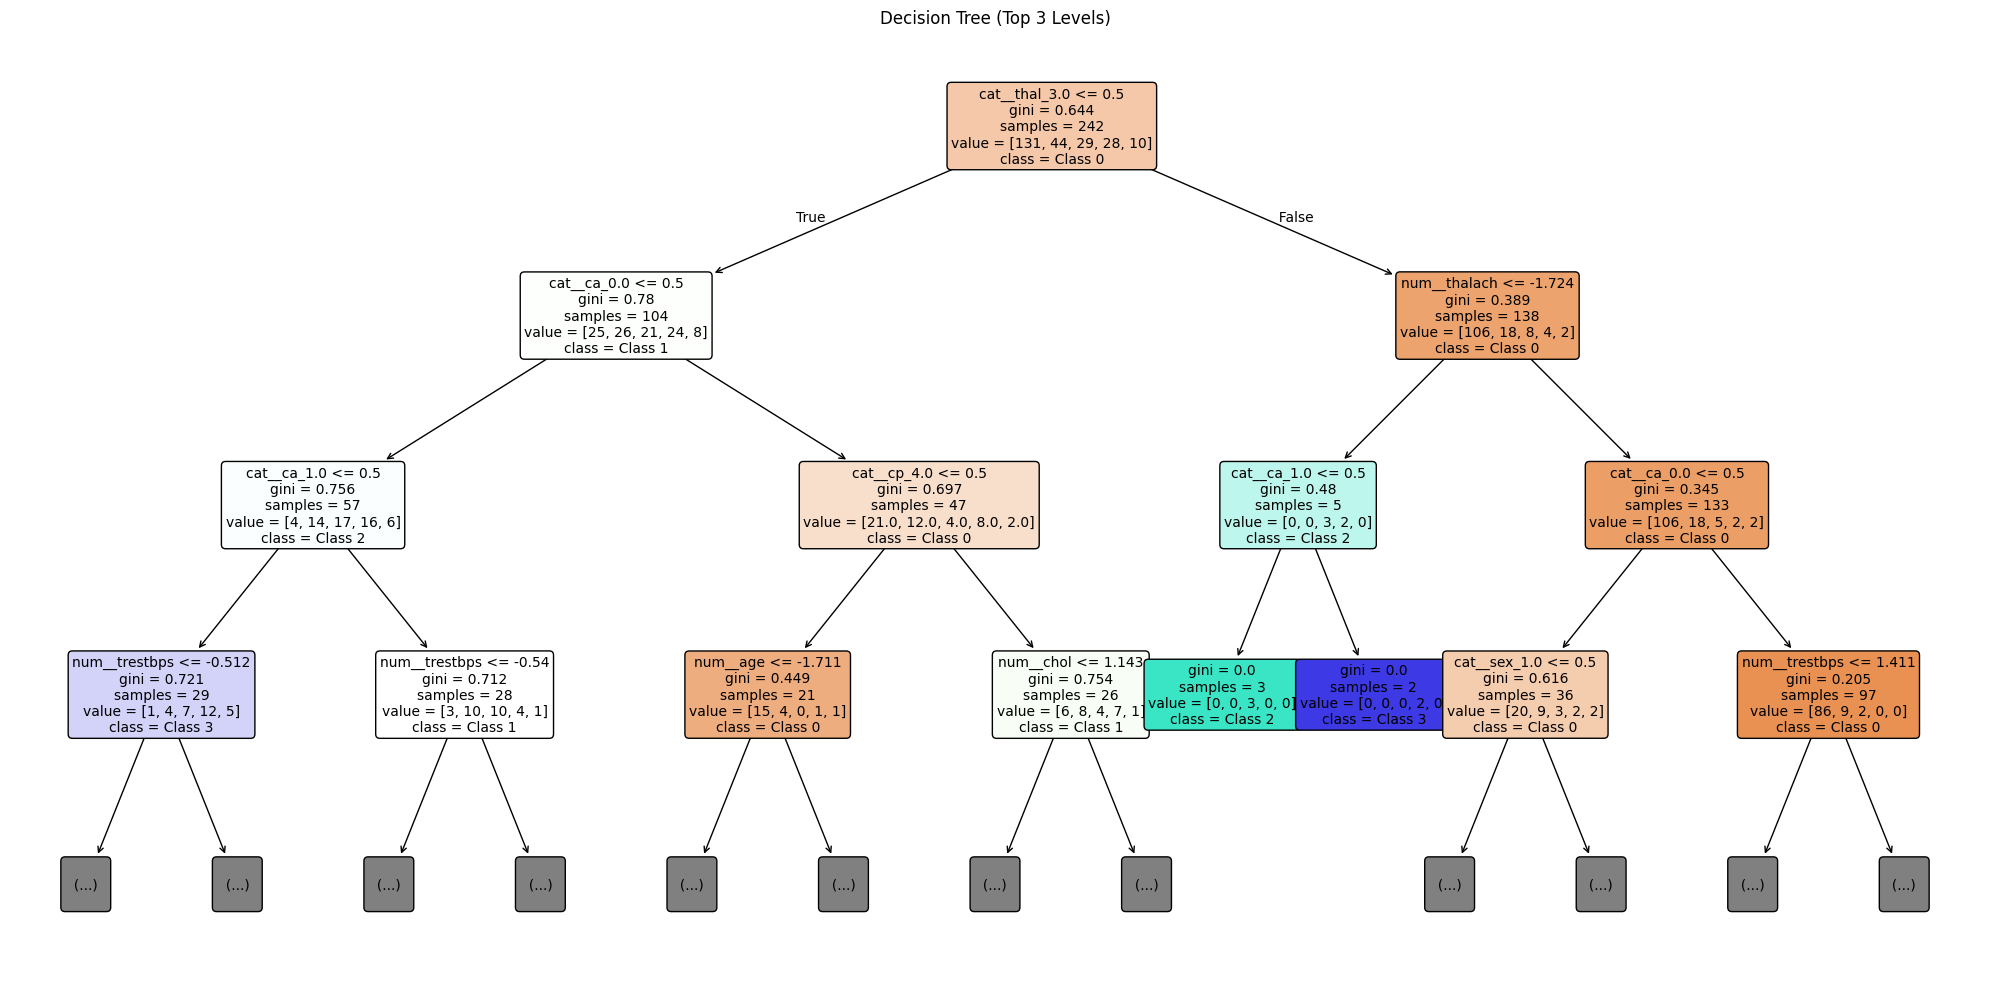

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import plot_tree

fitted_prep = dt_pipeline.named_steps['preprocessor']
fitted_tree = dt_pipeline.named_steps['classifier']
feature_names = fitted_prep.get_feature_names_out()

plt.figure(figsize=(20,10))
plot_tree(fitted_tree,
          feature_names=feature_names,
          class_names=['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4'],
          filled=True, rounded=True,
          max_depth=3, fontsize=10)
plt.title("Decision Tree (Top 3 Levels)")
plt.tight_layout()
plt.show()

           feature  importance
2        num__chol    0.139062
1    num__trestbps    0.136443
25   cat__thal_3.0    0.136186
3     num__thalach    0.109556
0         num__age    0.092125
4     num__oldpeak    0.089710
21     cat__ca_0.0    0.057926
19  cat__slope_2.0    0.042212
22     cat__ca_1.0    0.029896
11    cat__fbs_0.0    0.024057


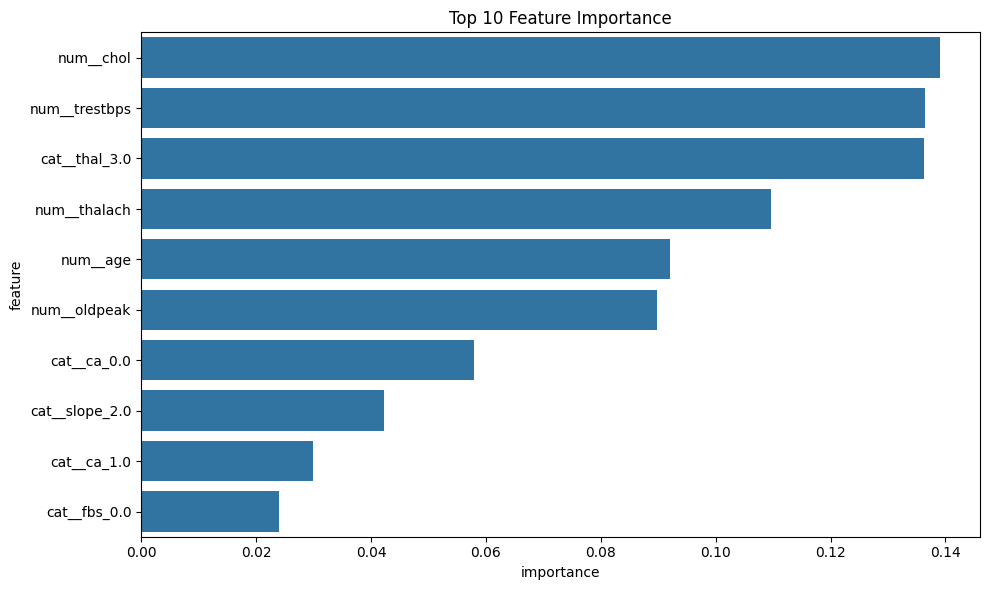

In [10]:
importance = pd.DataFrame({
    'feature':    feature_names,
    'importance': fitted_tree.feature_importances_
}).sort_values('importance', ascending=False)

print(importance.head(10))

plt.figure(figsize=(10,6))
sns.barplot(data=importance.head(10), x='importance', y='feature')
plt.title("Top 10 Feature Importance")
plt.tight_layout()
plt.show()